> **Notes: the words to remember**
>
> - **figure**: the whole picture, like a sheet of paper.
> - **axes** (`ax`): one chart on the figure, with its own x-axis and y-axis.
> - `fig, ax = plt.subplots()`: makes a new figure with one axes on it. We draw *on* the axes.
> - **histogram**: divides the values into intervals and counts how many fall in each one.
> - **bins**: the intervals of a histogram. More bins give a more detailed picture.
> - `dropna()`: removes the missing values. A chart can only draw what exists.
> - `plt.show()`: shows the picture.

In [85]:
def pp(msg=None, value=None):
    if msg is not None:
        print(msg)
    if value is not None:
        print(value)
    print('=' * 100)

1 Set up, and the first histogram
Import the libraries, choose the theme whitegrid, and load the table with parse_dates.
Draw a histogram of number_of_reviews with pure matplotlib (ax.hist, 50 bins). What do
you see? Then draw the same with seaborn (sns.histplot), with a title that says what we
see and names on both axes. How is it different?

(4574, 73)


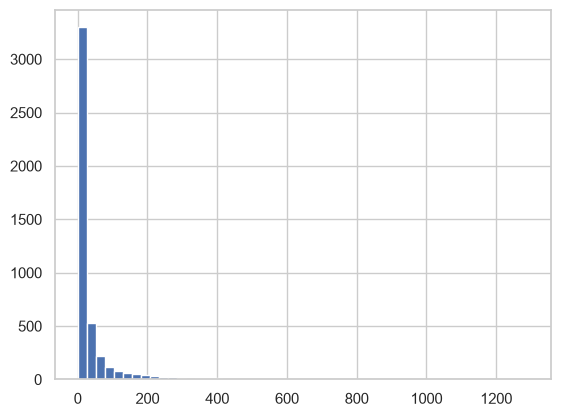

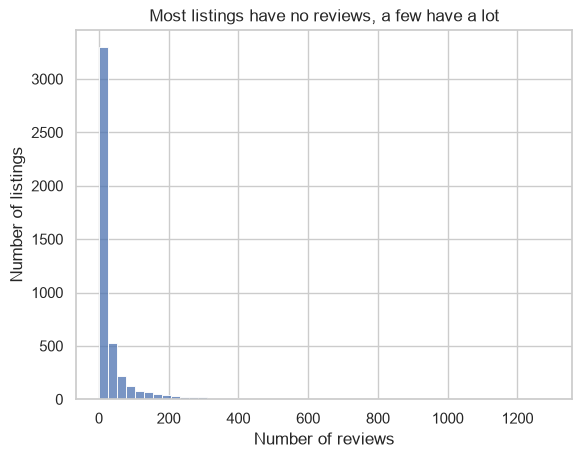

In [86]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

sns.set_theme(style='whitegrid')

date_columns = ['last_scraped', 'calendar_last_scraped', 'first_review', 'last_review']
listings = pd.read_csv('listings_clean.csv', parse_dates=date_columns)
pp(listings.shape)

fig, ax = plt.subplots()
ax.hist(listings['number_of_reviews'].dropna(), bins=50)
plt.show()


fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)
ax.set_title('Most listings have no reviews, a few have a lot')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')

plt.show()

2 Mean, median and the fence
Calculate the median, the mean and the upper fence of number_of_reviews with the IQR
rule (the same as in lab 6). Draw the histogram again, with a vertical line for each of
them, a label on each line and a legend. Which line is furthest to the right, and why?

Answer:
Upper fence, because it limits the range (lower/upper).

Median:
9.0
Mean:
35.75404459991255
Upper fence:
69.5


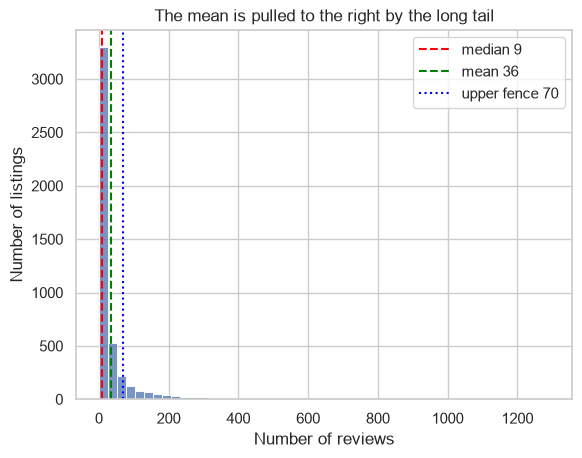

In [87]:
median = listings['number_of_reviews'].median()
mean = listings['number_of_reviews'].mean()
q1 = listings['number_of_reviews'].quantile(0.25)
q3 = listings['number_of_reviews'].quantile(0.75)
iqr = q3 - q1
upper = q3 + 1.5 * iqr
lower = q1 - 1.5 * iqr

pp("Median:", median)
pp("Mean:", mean)
pp("Upper fence:", upper)
# pp("Lower fence:", lower)

fig, ax = plt.subplots()
sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=ax)

ax.axvline(median, color='red', linestyle='--', label=f'median {median:,.0f}')
ax.axvline(mean, color='green', linestyle='--', label=f'mean {mean:,.0f}')
ax.axvline(upper, color='blue', linestyle=':', label=f'upper fence {upper:,.0f}')
# ax.axvline(upper, color='gray', linestyle=':', label=f'lower fence {lower:,.0f}')

ax.set_title('The mean is pulled to the right by the long tail')
ax.set_xlabel('Number of reviews')
ax.set_ylabel('Number of listings')
ax.legend()

plt.show()

3 With and without the outliers
Mark the outliers in a column reviews_outlier. Draw two charts side by side with
plt.subplots(1, 2): all listings on the left, and without the outliers on the right. Put the
number of outliers in the title of the right chart. What does the right chart show that the
left one does not?

Answer:
The right chart shows tail values.

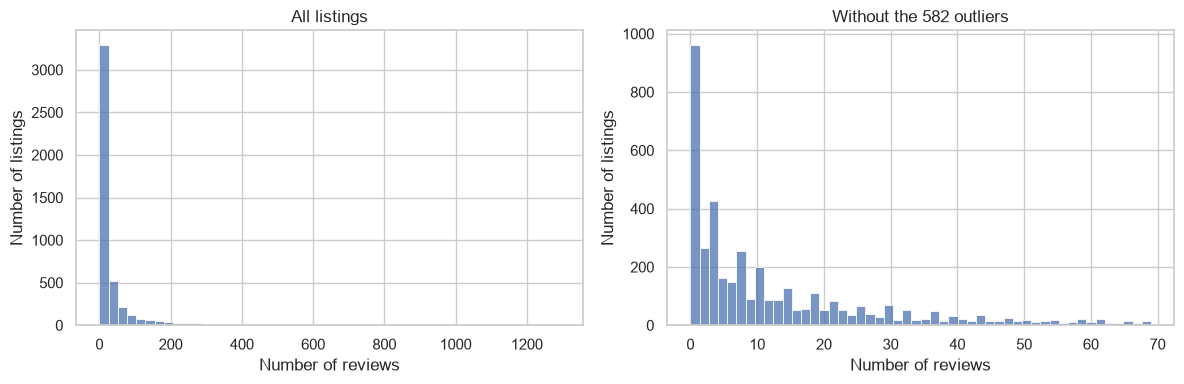

In [88]:
listings['reviews_outlier'] = listings['number_of_reviews'] > upper

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=listings, x='number_of_reviews', bins=50, ax=axes[0])
sns.histplot(data=listings[~listings['reviews_outlier']], x='number_of_reviews', bins=50, ax=axes[1])

axes[0].set_title('All listings')
axes[1].set_title('Without the 582 outliers')

for ax in axes:
    ax.set_xlabel('Number of reviews')
    ax.set_ylabel('Number of listings')

plt.tight_layout()
plt.show()

4 The boxplot
Draw a boxplot of number_of_reviews for the two big room types (Entire home/apt and
Private room; use isin). Most of the picture is empty, so show only 0 to 300 with set_ylim.
Say in the title how many listings with more than 300 reviews are outside the picture
(count them first). Which room type has the higher median? Note: a boxplot can show a
red MatplotlibDeprecationWarning about vert. It is a warning, not an error, and your chart
is fine.

Answer:
Private rooms have higher median.

C:\Users\User\AppData\Local\Temp\ipykernel_9660\3097290815.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  more_than_300 = two_types[listings['number_of_reviews'] > 300]


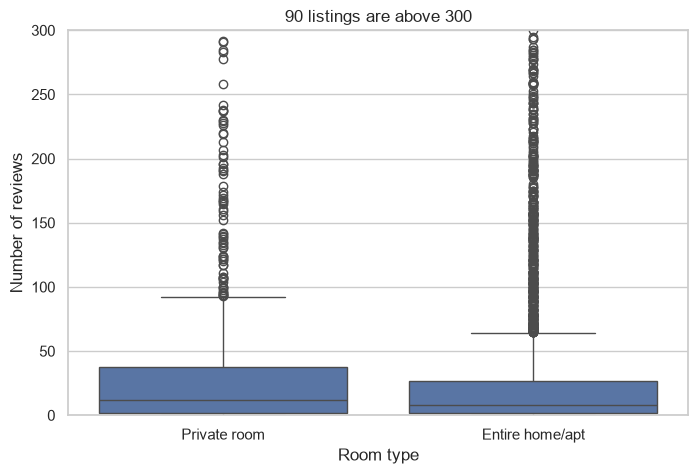

In [89]:
two_types = listings[listings['room_type'].isin(['Entire home/apt', 'Private room'])]
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=two_types, x= 'room_type', y='number_of_reviews', ax=ax)

more_than_300 = two_types[listings['number_of_reviews'] > 300]

ax.set_ylim(0,300)
# ax.set_ylim(0,50)
ax.set_title(f'{len(more_than_300)} listings are above 300')
ax.set_xlabel('Room type')
ax.set_ylabel('Number of reviews')

plt.show()

In [90]:
check_plot = (listings[listings['room_type'].isin(['Private room', 'Entire home/apt'])]
    .groupby('room_type')['number_of_reviews']
    .describe()
)
pp(check_plot)

                  count       mean        std  min  25%   50%   75%     max
room_type                                                                  
Entire home/apt  3760.0  34.231649  76.464806  0.0  2.0   8.0  27.0  1293.0
Private room      787.0  40.537484  84.363382  0.0  2.0  12.0  38.0   867.0
